# Uniform Manifold Approximation and Projection (UMAP)
2018

## Loading Dataset
- Optical Recognition of Handwritten Digits (UCI ML) via `sklearn.datasets.load_digits`
  - Handwritten numbers from 0 to 9
  - 8x8 gray scale, pixel values 0-16
  - Not MNIST (28x28, 70,000 samples)

[1245  220 1518  438 1270  832  692 1309 1101 1742]


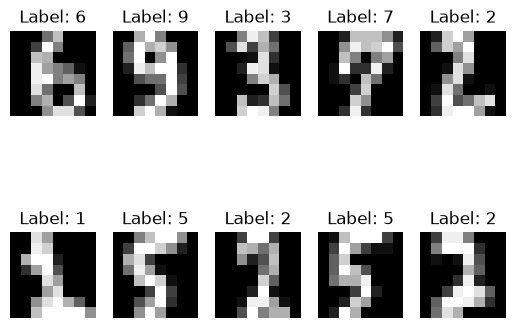

In [13]:
from sklearn.datasets import load_digits
digits = load_digits()

dig = False 
if dig:
    print("####### Dive into the data #######")
    print(digits.data.shape) # look into the shape of the data
    
    print(digits.data) # look into the data roughly
    print(digits.data[0]) # look into the first data
    
    print(digits.target) # look into the target roughly
    print(len(digits.target)) # look into the length of the target
    
    print(type(digits.data)) # look into the type of the data
    print(type(digits.data[0])) # look into the type of the data
    
    print("\n####### Visualize the data #######")

# Visualize the data 
# randomly select 10 images from the dataset and plot them
import matplotlib.pyplot as plt # needed for plotting

import numpy as np
seed = 42
np.random.seed(seed)

indices = np.random.choice(len(digits.data), size=10, replace=False)
print(indices) # look into the indices

for i, idx in enumerate(indices):
    plt.subplot(2, 5, i + 1)
    plt.imshow(digits.data[idx].reshape(8, 8), cmap='gray')
    plt.title(f"Label: {digits.target[idx]}")
    plt.axis('off')

- the number of sample is 1797
- "64" is the dimension of each data, thus picture is 8 times 8 square
- target is the "label" of each sample
- data type is numpy.ndarray
- 

In [24]:
import umap

# Run UMAP to reduce the dimensionality of the data to 2D
X_reduced = umap.UMAP(n_components=2, random_state=20).fit_transform(digits.data)


/Users/nkn4ryu/ghq/github.com/shiryu-nakano/tutorials/data_science_turorial/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


In [23]:
digits.target_names

print(digits.target)
labels = digits.target == 0
print(labels) # look into the boolean array

[0 1 2 ... 8 9 8]
[ True False False ... False False False]


c_plot_bool:  [ True False False ... False False False]
c_plot_bool:  [False  True False ... False False False]
c_plot_bool:  [False False  True ... False False False]
c_plot_bool:  [False False False ... False False False]
c_plot_bool:  [False False False ... False False False]
c_plot_bool:  [False False False ... False False False]
c_plot_bool:  [False False False ... False False False]
c_plot_bool:  [False False False ... False False False]
c_plot_bool:  [False False False ...  True False  True]
c_plot_bool:  [False False False ... False  True False]


Text(0, 0.5, 'UMAP 2')

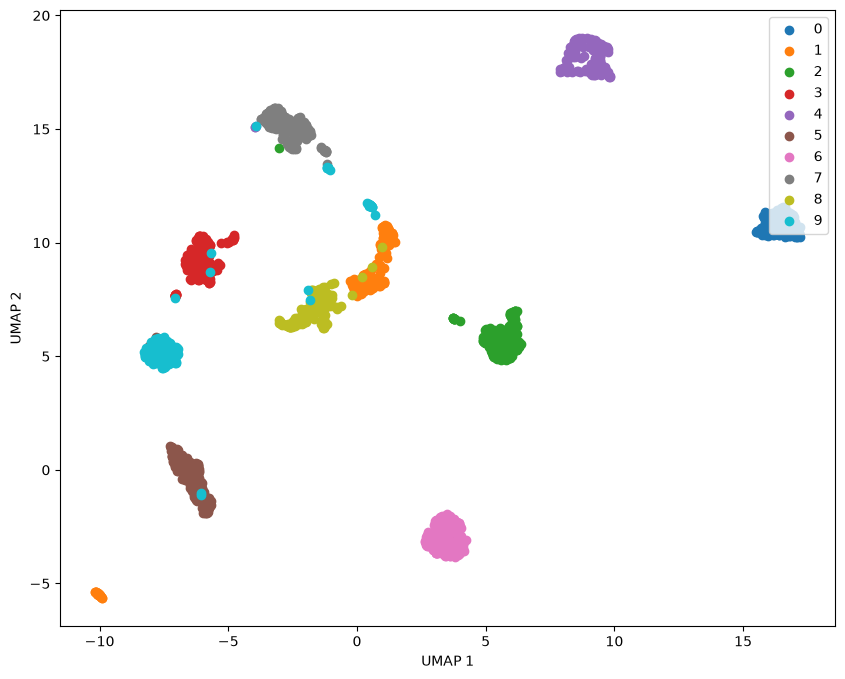

In [25]:
plt.figure(figsize=(10,8))
for each_label in digits.target_names:
    c_plot_bool = digits.target == each_label # 意味？→
    print("c_plot_bool: ", c_plot_bool) # look into the boolean array
    plt.scatter(X_reduced[c_plot_bool,0], X_reduced[c_plot_bool,1], label="{}".format(each_label))

plt.legend(loc="upper right")
plt.xlabel("UMAP 1")
plt.ylabel("UMAP 2")

# random states と n_neighborsについて

## ``random states``を変えながら10通り実行する


[1245  220 1518  438 1270  832  692 1309 1101 1742]


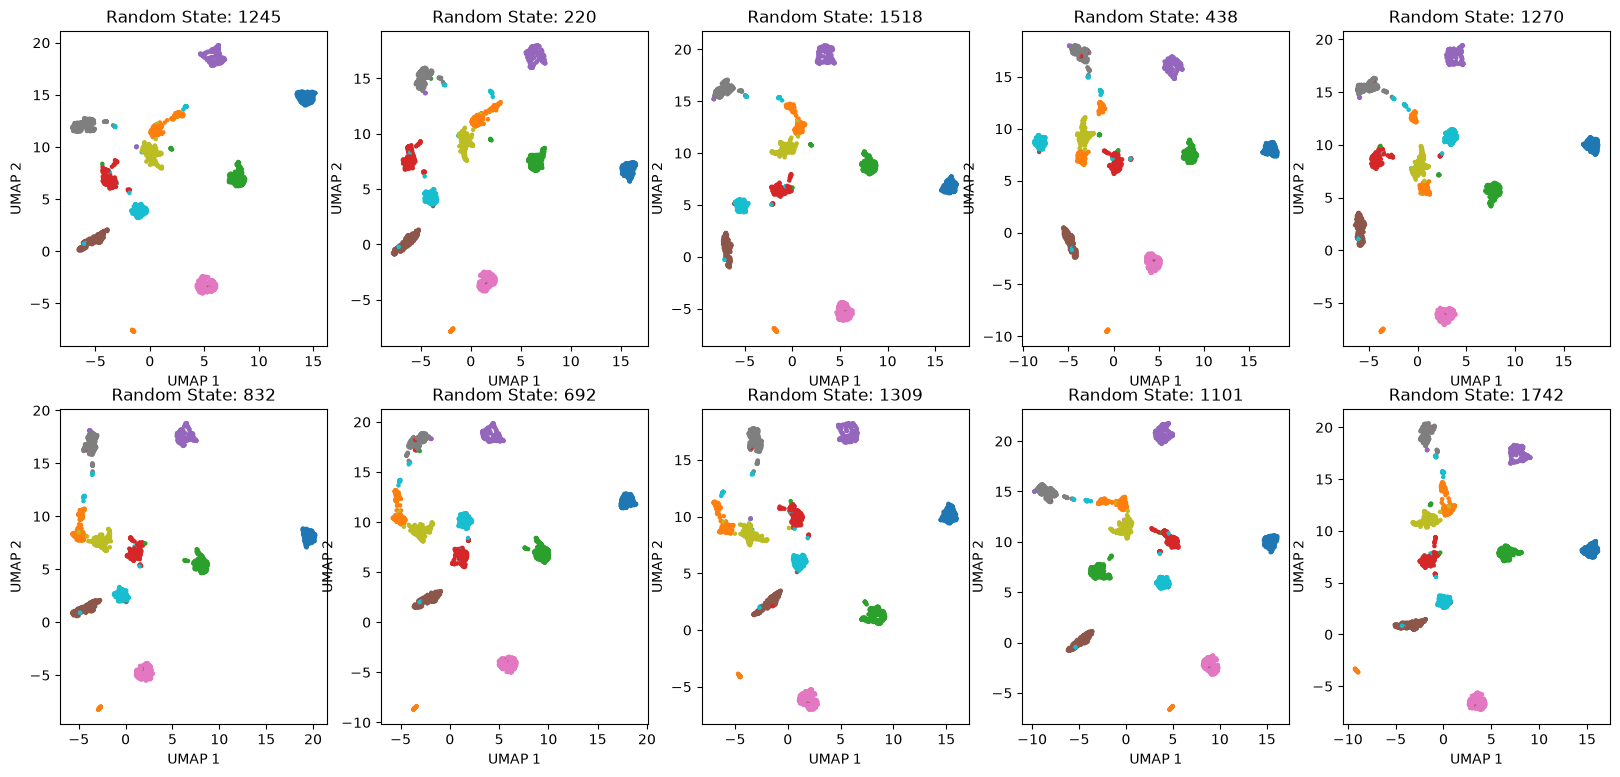

In [35]:
# random states を変えながら10通り
import matplotlib.pyplot as plt # needed for plotting
import numpy as np
import warnings
warnings.filterwarnings("ignore", message="n_jobs value .* overridden")

seed = 42
np.random.seed(seed)

random_states = np.random.choice(len(digits.data), size=10, replace=False)
print(random_states) # look into the random states


X_reduced_list = []
for random_state in random_states:
    X_reduced = umap.UMAP(n_components=2, random_state=random_state).fit_transform(digits.data)
    X_reduced_list.append(X_reduced)

fig, axes = plt.subplots(2, 5, figsize=(20, 9))
for i, ax in enumerate(axes.flat):
    ax.scatter(X_reduced_list[i][:, 0], X_reduced_list[i][:, 1], c=digits.target, cmap='tab10', s=5)
    ax.set_title(f"Random State: {random_states[i]}")
    ax.set_xlabel("UMAP 1")
    ax.set_ylabel("UMAP 2")


##  ``n_neighbors``を変えながら10通り実行する
- 10, 15, 20 くらいがいい？

/Users/nkn4ryu/ghq/github.com/shiryu-nakano/tutorials/data_science_turorial/.venv/lib/python3.12/site-packages/sklearn/manifold/_spectral_embedding.py:325: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(
/Users/nkn4ryu/ghq/github.com/shiryu-nakano/tutorials/data_science_turorial/.venv/lib/python3.12/site-packages/sklearn/manifold/_spectral_embedding.py:390: RuntimeWarning: ARPACK has failed, falling back to LOBPCG.
  warnings.warn("ARPACK has failed, falling back to LOBPCG.", RuntimeWarning)
/Users/nkn4ryu/ghq/github.com/shiryu-nakano/tutorials/data_science_turorial/.venv/lib/python3.12/site-packages/sklearn/manifold/_spectral_embedding.py:463: UserWarning: Exited at iteration 50 with accuracies 
[2.48955574e-05 5.19663846e-06 1.87311793e-04 5.93252765e-05]
not reaching the requested tolerance 5.9157609939575195e-06.
Use iteration 50 instead with accuracy 
6.918231632157644e-05.

  _, diffusion_map = lobpcg(
/Users/nkn4ryu/ghq/gi

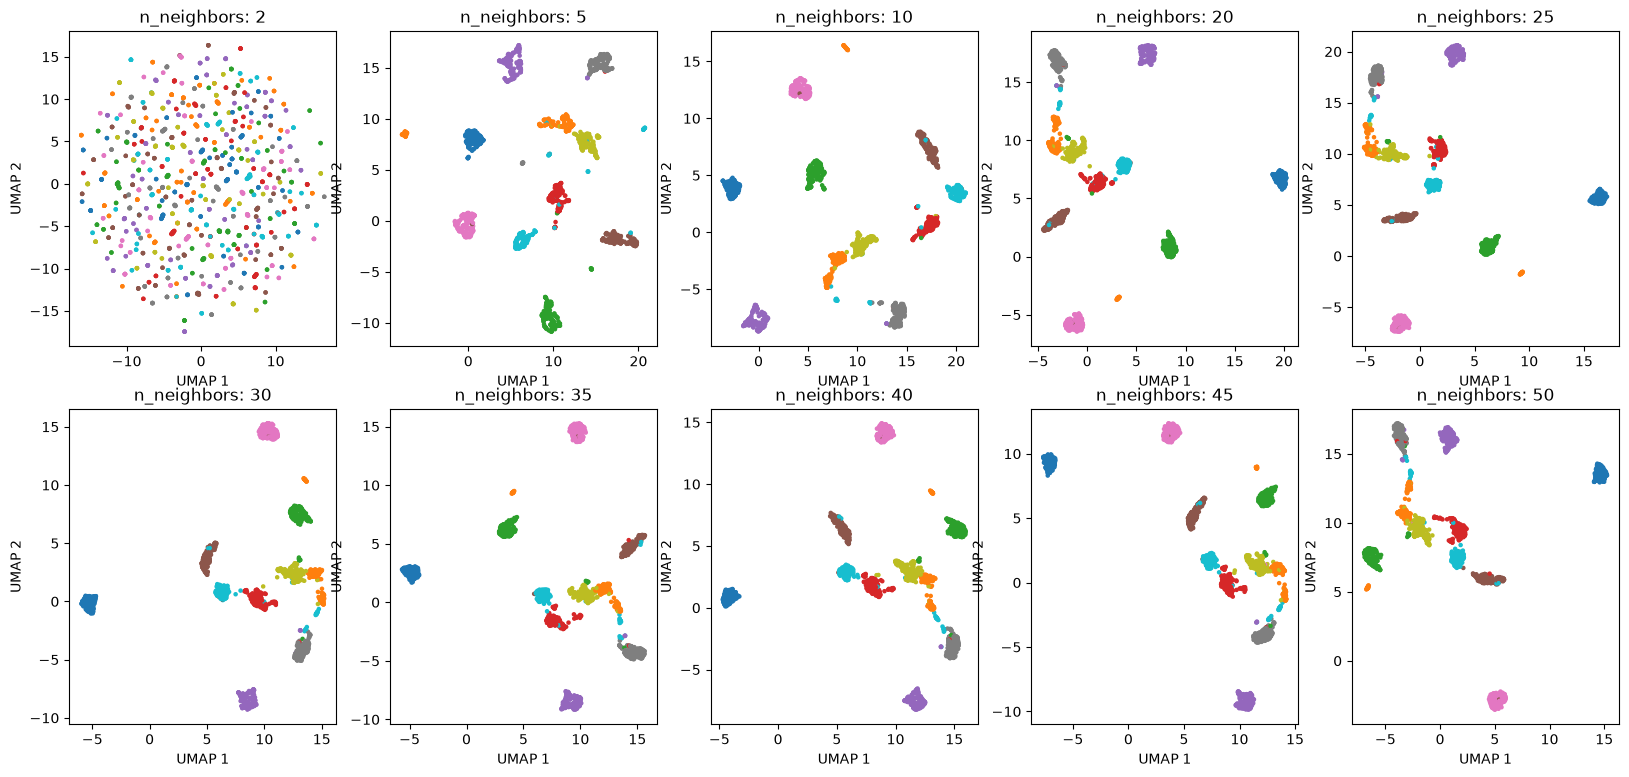

In [37]:
# n_neighbors を変えながら10通り

# random states を変えながら10通り
import matplotlib.pyplot as plt # needed for plotting
import numpy as np
import warnings
warnings.filterwarnings("ignore", message="n_jobs value .* overridden")

seed = 42
np.random.seed(seed)
# n_neighbors を変えながら10通り
n_neighbors_list = [2, 5, 10, 20, 25, 30, 35, 40, 45, 50]


X_reduced_list = []
for n_neighbors in n_neighbors_list:
    X_reduced = umap.UMAP(n_components=2, n_neighbors=n_neighbors).fit_transform(digits.data)
    X_reduced_list.append(X_reduced)

fig, axes = plt.subplots(2, 5, figsize=(20, 9))
for i, ax in enumerate(axes.flat):
    ax.scatter(X_reduced_list[i][:, 0], X_reduced_list[i][:, 1], c=digits.target, cmap='tab10', s=5)
    ax.set_title(f"n_neighbors: {n_neighbors_list[i]}")
    ax.set_xlabel("UMAP 1")
    ax.set_ylabel("UMAP 2")


# 複数のデータセットで実行してみる
MNIST, Fashion-MNIST, CIFAR-10 に対して UMAP を実行する．
- MNIST, Fashion-MNIST は `fetch_openml` で OpenML から取得する
  - 初回はダウンロードされ，`data_science_turorial/datasets/openml/` に保存される（2回目以降はローカルから読み込む）
- CIFAR-10 は TensorFlow Datasets が取得・展開済みのバイナリ版（`datasets/tensorflow_datasets/`）を読み込む
  - OpenML からのダウンロードは途中で切れやすく，公式配布元からは時間がかかるため
- 保存先は共通関数のセルの `DATASETS_DIR` で変更できる（どちらも git 管理対象外）
- 各データ 60,000〜70,000 件あるので，計算時間短縮のため 10,000 件をランダムに抽出して使う
- 画素値は 0〜255 なので 255 で割って [0, 1] に正規化する

In [53]:
# 3つのデータセットで共通して使う関数
import os
import glob

import numpy as np
import matplotlib.pyplot as plt
import umap
from sklearn.datasets import fetch_openml

# データの置き場所（このノートブックからの相対パス → data_science_turorial/datasets/）
DATASETS_DIR = "../datasets"
DATA_HOME = os.path.join(DATASETS_DIR, "openml")  # MNIST, Fashion-MNIST の保存先
# CIFAR-10 は TensorFlow Datasets が取得・展開済みのバイナリ版を使う
CIFAR10_DIR = os.path.join(DATASETS_DIR, "tensorflow_datasets", "downloads", "extracted")


def load_openml(name, data_home=DATA_HOME):
    """OpenML からデータ全件を取得し，画素値を [0, 1] に正規化する"""
    # read_csv_kwargs={"dtype": None}: pandas 3 ではラベルが整数カテゴリとして読まれ，
    # sklearn 側でエラーになるため，カテゴリ型にせずそのまま数値として読み込む
    X, y = fetch_openml(name, version=1, return_X_y=True, as_frame=False, data_home=data_home,
                        read_csv_kwargs={"dtype": None})
    return X.astype(np.float32) / 255.0, y.astype(int)


def load_cifar10(data_dir=CIFAR10_DIR):
    """CIFAR-10 全件（train 50,000 + test 10,000）をバイナリ版から読み込み，画素値を [0, 1] に正規化する"""
    # 展開先のフォルダ名にはハッシュが付くので glob で探す
    matches = glob.glob(os.path.join(data_dir, "*", "cifar-10-batches-bin"))
    if not matches:
        raise FileNotFoundError(f"cifar-10-batches-bin が {data_dir} の下に見つかりません")
    batch_dir = matches[0]

    # 各 .bin は 10,000 行 × 3073 バイト：先頭1バイトがラベル，残り3072バイトが画素（R, G, B の順）
    names = [f"data_batch_{i}.bin" for i in range(1, 6)] + ["test_batch.bin"]
    rows = np.concatenate([
        np.fromfile(os.path.join(batch_dir, name), dtype=np.uint8).reshape(-1, 3073)
        for name in names
    ])
    X = rows[:, 1:].astype(np.float32) / 255.0
    y = rows[:, 0].astype(int)
    return X, y


def random_subsample(X, y, n_samples=10000, seed=42):
    """X, y から n_samples 件をランダムに（重複なしで）抽出する"""
    rng = np.random.default_rng(seed)
    idx = rng.choice(len(X), size=n_samples, replace=False)
    return X[idx], y[idx]


def show_samples(images, y, class_names, cmap=None):
    """先頭10枚の画像をラベル付きで表示する"""
    fig, axes = plt.subplots(2, 5, figsize=(10, 4))
    for i, ax in enumerate(axes.flat):
        ax.imshow(images[i], cmap=cmap)
        ax.set_title(class_names[y[i]])
        ax.axis('off')
    plt.show()


def plot_umap(X_reduced, y, class_names, title):
    """UMAP の2次元埋め込みをクラスごとに色分けして描画する"""
    plt.figure(figsize=(10, 8))
    for label, name in enumerate(class_names):
        mask = y == label  # このクラスのサンプルだけ True
        plt.scatter(X_reduced[mask, 0], X_reduced[mask, 1], s=3, label=name)
    plt.legend(markerscale=4, loc="upper right")
    plt.title(title)
    plt.xlabel("UMAP 1")
    plt.ylabel("UMAP 2")
    plt.show()

all: (70000, 784) (70000,)
labels: [6903 7877 6990 7141 6824 6313 6876 7293 6825 6958]
subsample: (10000, 784) (10000,)


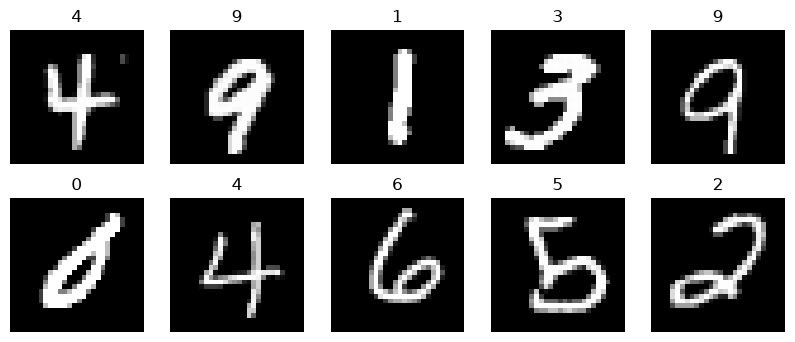

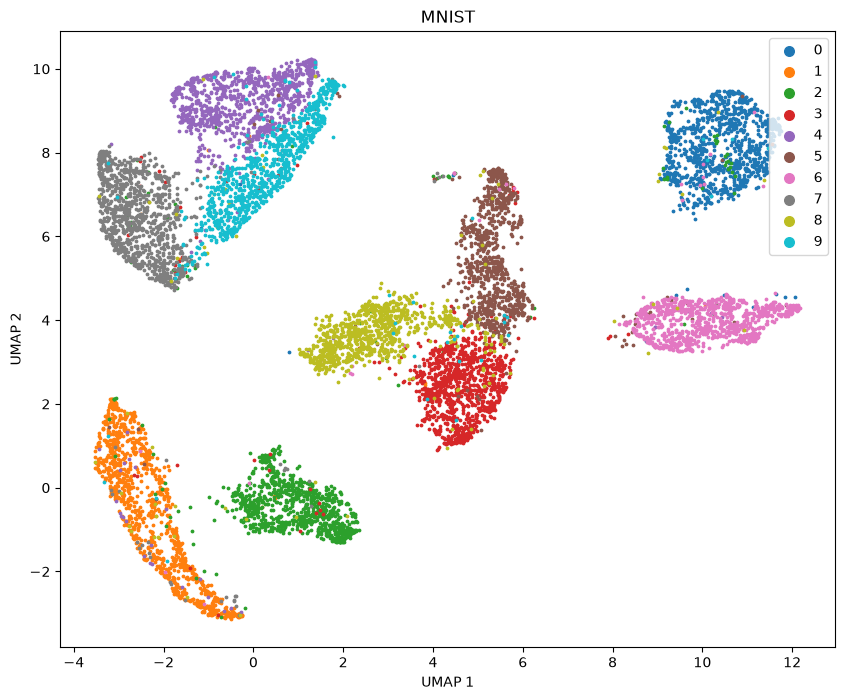

In [42]:
# MNIST: 手書き数字 0〜9，28x28 グレースケール（784次元），70,000件
mnist_classes = [str(i) for i in range(10)]

# 全件を取得して構造を確認
X_mnist_all, y_mnist_all = load_openml("mnist_784")
print("all:", X_mnist_all.shape, y_mnist_all.shape)
print("labels:", np.bincount(y_mnist_all))  # クラスごとの件数

# 10,000件をランダムに抽出
X_mnist, y_mnist = random_subsample(X_mnist_all, y_mnist_all, n_samples=10000)
print("subsample:", X_mnist.shape, y_mnist.shape)

show_samples(X_mnist.reshape(-1, 28, 28), y_mnist, mnist_classes, cmap='gray')

X_mnist_reduced = umap.UMAP(n_components=2, random_state=42).fit_transform(X_mnist)
plot_umap(X_mnist_reduced, y_mnist, mnist_classes, "MNIST")

all: (70000, 784) (70000,)
labels: [7000 7000 7000 7000 7000 7000 7000 7000 7000 7000]
subsample: (10000, 784) (10000,)


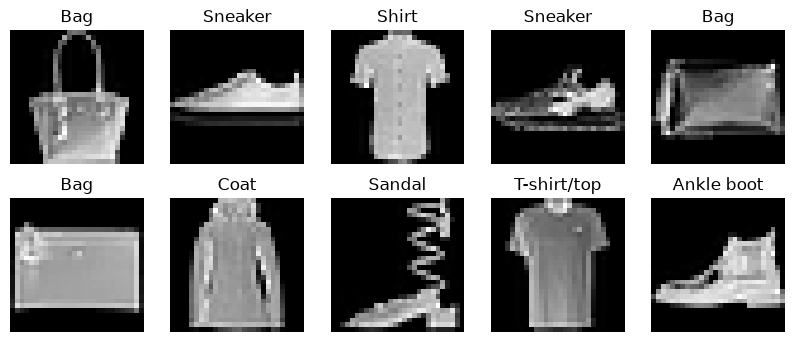

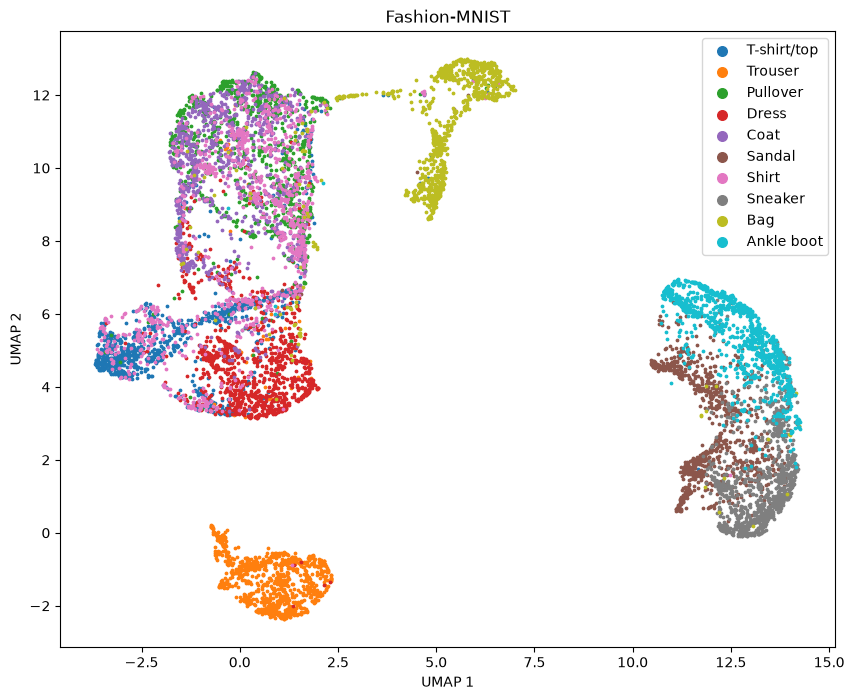

In [43]:
# Fashion-MNIST: 衣類10クラス，28x28 グレースケール（784次元），70,000件
fashion_classes = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
                   "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

# 全件を取得して構造を確認
X_fashion_all, y_fashion_all = load_openml("Fashion-MNIST")
print("all:", X_fashion_all.shape, y_fashion_all.shape)
print("labels:", np.bincount(y_fashion_all))  # クラスごとの件数

# 10,000件をランダムに抽出
X_fashion, y_fashion = random_subsample(X_fashion_all, y_fashion_all, n_samples=10000)
print("subsample:", X_fashion.shape, y_fashion.shape)

show_samples(X_fashion.reshape(-1, 28, 28), y_fashion, fashion_classes, cmap='gray')

X_fashion_reduced = umap.UMAP(n_components=2, random_state=42).fit_transform(X_fashion)
plot_umap(X_fashion_reduced, y_fashion, fashion_classes, "Fashion-MNIST")

all: (60000, 3072) (60000,)
labels: [6000 6000 6000 6000 6000 6000 6000 6000 6000 6000]
subsample: (10000, 3072) (10000,)


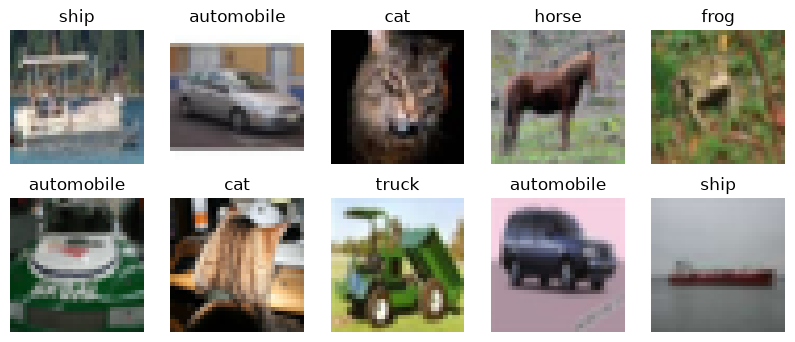

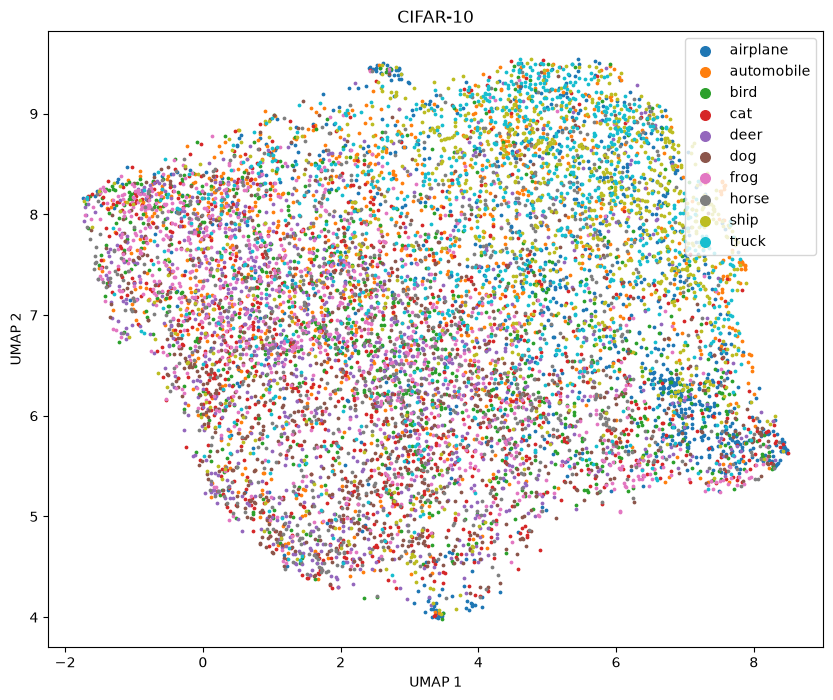

In [54]:
# CIFAR-10: 物体10クラス，32x32 カラー（3072次元 = 3ch x 32 x 32），60,000件
# 1行は [R 1024画素, G 1024画素, B 1024画素] の順に並んでいるので，表示用に (32, 32, 3) へ並べ替える
cifar_classes = ["airplane", "automobile", "bird", "cat", "deer",
                 "dog", "frog", "horse", "ship", "truck"]

# 全件を読み込んで構造を確認（TensorFlow Datasets が展開済みのバイナリ版から）
X_cifar_all, y_cifar_all = load_cifar10()
print("all:", X_cifar_all.shape, y_cifar_all.shape)
print("labels:", np.bincount(y_cifar_all))  # クラスごとの件数

# 10,000件をランダムに抽出
X_cifar, y_cifar = random_subsample(X_cifar_all, y_cifar_all, n_samples=10000)
print("subsample:", X_cifar.shape, y_cifar.shape)

show_samples(X_cifar.reshape(-1, 3, 32, 32).transpose(0, 2, 3, 1), y_cifar, cifar_classes)

X_cifar_reduced = umap.UMAP(n_components=2, random_state=42).fit_transform(X_cifar)
plot_umap(X_cifar_reduced, y_cifar, cifar_classes, "CIFAR-10")